In [4]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy

In [5]:
# Connect to the 'general' database as a 'read-only' user
eng = nivapy.da.connect_postgis()

Connection successful.


## Add vassdragsområde and reginer information

For use in cross validation/grouping

**To do: add regine**

In [6]:
cat_fpath = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/catchments_vm-rivs-quant-oc_v3-full.gpkg"
cat_id_col = "site_code"

cat_gdf = gpd.read_file(cat_fpath)
cat_gdf.head()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.290760,"POLYGON ((305560 6548480, 305560 6548500, 3055..."


In [8]:
# Add vassdragsområde. For this to work, cat_id_col must be the full site code, not the site id

# For index values with a valid 3-digit prefix, add to new col.
# if no valid prefix, add NaN
cat_gdf["vassomnr"] = (
    cat_gdf[cat_id_col]
    .str.extract(r"^(\d{3})-", expand=False)
)

# Add vassdragsområde numbers for site codes that don't follow the standard 'nnn-' format

# Rows that don't match the expected format
invalid_rows = cat_gdf[~cat_gdf[cat_id_col].str.match(r"^\d{3}-", na=False)]
print("Rows without vassom info:", len(invalid_rows))
# display(invalid_rows.head())

# Read vassdragsområder polygons
vassom_gdf = nivapy.da.read_postgis('physical', 'norway_nve_vassdragomrade_poly', eng)
# vassom_gdf.head()

# Create point GeoDataFrame
odd_pts_gdf = gpd.GeoDataFrame(
    invalid_rows,
    geometry=gpd.points_from_xy(invalid_rows.lon, invalid_rows.lat),
    crs="EPSG:4326",
)

# Spatial join with vassdragsområde polys
invalid_rows = gpd.sjoin(
    odd_pts_gdf[[cat_id_col, 'geometry']],
    vassom_gdf[["vassdragsomradenr", "geom"]],
    how="left",
    predicate="within",
)

invalid_rows = invalid_rows.rename(
    columns={"vassdragsomradenr": "vassomnr"}
)

# Fill vassom number into cat_gdf
# Create lookup from site_code -> vassomnr
lookup = invalid_rows.set_index(cat_id_col)["vassomnr"]
cat_gdf["vassomnr"] = cat_gdf["vassomnr"].fillna(
    cat_gdf[cat_id_col].map(lookup)
)

# Make df ready for joining into main table
cat_df = cat_gdf.drop(['site_id', 'geometry'], axis=1).set_index('site_code').copy()

cat_df.tail()

Rows without vassom info: 23


,lon,lat,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,vassomnr
site_code,,,,,,,,,,
313-99151,12.111818,59.990523,Hesbølsjøen utløp,2024,2024,1.0,5,5.00,141.833882,313
314-46646,11.699073,59.634394,"Åkevannet, utløp",2011,2022,11.0,4,0.36,8.233540,314
314-48074,11.924796,59.747409,"Røvatnet, utløp",2011,2011,1.0,1,1.00,34.437679,314
314-62046,11.730778,59.479630,Håbyelva,2012,2012,1.0,2,2.00,1.341151,314
314-89994,11.771138,59.773726,"Store Lyseren, utløp",2011,2011,1.0,1,1.00,3.076372,314


## Save

In [10]:
# Save updated cat_df
catchment_set = "monitored-oc-catchs"
out_folder = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
out_fpath = os.path.join(out_folder, f"{catchment_set}_static_vassom-reginer.csv")
cat_df[['vassomnr']].to_csv(out_fpath)

## QC

Total sites: 8482
Unique vassomnr: 209
Sites with NaN vassomnr: 0

Top 5 vassomnr by site count:
vassomnr
002    1086
012     930
016     371
015     337
022     181
Name: count, dtype: int64


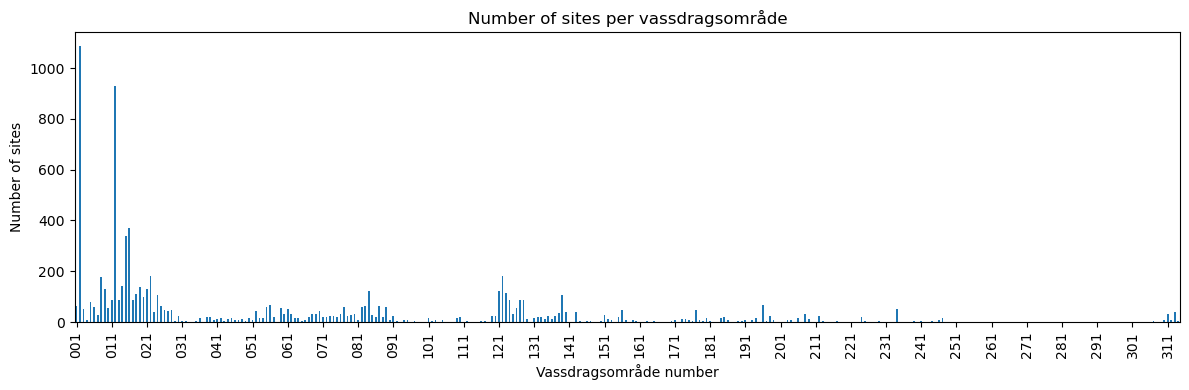

In [16]:
# QC
print(f"Total sites: {len(cat_df)}")
print(f"Unique vassomnr: {cat_df['vassomnr'].nunique()}")
print(f"Sites with NaN vassomnr: {cat_df['vassomnr'].isna().sum()}")
print("\nTop 5 vassomnr by site count:")
print(cat_df['vassomnr'].value_counts().head(5))

# Quick plot
counts = (
    cat_df.groupby("vassomnr")
    .size()
    .reindex([f"{i:03d}" for i in range(1, 315)], fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 4))
counts.plot(kind="bar", ax=ax)
ax.set_xlabel("Vassdragsområde number")
ax.set_ylabel("Number of sites")
ax.set_title("Number of sites per vassdragsområde")

# Show every 10th label to reduce clutter
ax.set_xticks(range(0, 314, 10))
ax.set_xticklabels([f"{i:03d}" for i in range(1, 315, 10)])
plt.tight_layout()
plt.show()

In [12]:
cat_df.loc[cat_df['vassomnr'] == '234']

,lon,lat,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,vassomnr
site_code,,,,,,,,,,
234-106348,27.476470,70.023920,Sirpmájohka ved boligfelt,2021,2021,1.0,4,4.00,9.814617,234
234-106349,28.167030,70.121180,Árbantjohka Fielbmajohka st. 1,2021,2021,1.0,4,4.00,11.885454,234
234-106350,28.146050,70.123060,Árbantjohka Fielbmajohka st. 2,2021,2021,1.0,3,3.00,11.365767,234
234-106351,28.119180,70.112580,Árbantjohka Fielbmajohka st. 3,2021,2021,1.0,4,4.00,0.450059,234
234-13b,25.688190,69.200150,Mareveadji,2022,2022,1.0,156,156.00,37.734475,234
234-14,24.473300,69.390100,Cærrogæsjokka,2022,2023,1.4,355,246.04,44.360402,234
234-15,24.196780,69.339190,Liebetjohka,2023,2023,1.0,155,155.00,29.723586,234
234-28599,25.780663,69.352825,"Anarjohka 2, oppstrøms Cappesjohka",1992,2012,19.9,66,3.31,2796.468027,234
234-28601,25.213618,69.443804,"Karasjohka 1, Assebakti",1992,2025,33.0,236,7.15,4490.373723,234


This shows that spatial cross validation with leave-one-vassdragsområde-out at a time will be a bit challenging when it comes to Glomma (002) and Drammenselva (012), which account for a lot of the data points. Will probably have to rethink... Instead, add regine and use TEOTIL network functions to identify points upstream and downstream (on the main stem)?